# Conclusiones comparativas de subsets, variables y algoritmos

Este notebook selecciona automáticamente el subset recomendado para cada dataset, determina su mejor número de clusters (`k`), ajusta MiniBatch K-Means y muestra tamaños, medias originales por cluster y visualizaciones de apoyo.

**Criterio:** el mejor subset es el de mayor `score` medio en `recommended_features.csv`. Su `k` se elige dentro de `feature_selection_results.csv` maximizando `score`; los desempates favorecen mayor silhouette, mayor Calinski-Harabasz y menor Davies-Bouldin.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA

RANDOM_STATE = 42
PCA_SAMPLE_SIZE = 20_000
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

def encontrar_raiz(inicio=Path.cwd()):
    for ruta in [inicio, *inicio.parents]:
        if (ruta / "results" / "feature_selection" / "recommended_features.csv").exists():
            return ruta
    raise FileNotFoundError("No se encontró la raíz del proyecto.")

ROOT = encontrar_raiz()
import sys
sys.path.insert(0, str(ROOT / "code" / "03_modeling"))
from modeling_functions import fit_clustering_model
FEATURE_SELECTION_DIR = ROOT / "results" / "feature_selection"
RESULTS_DIR = ROOT / "results" / "multimodel"
PROFILES_DIR = ROOT / "results" / "profiles"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PROFILES_DIR.mkdir(parents=True, exist_ok=True)
DATASETS = {
    "hym": {
        "scaled": ROOT / "scaled_data" / "hym_scaled.csv",
        "original": ROOT / "extended_datasets" / "hym_model_extended.csv",
        "id_col": "customer_id",
        "titulo": "H&M",
    },
    "instacart": {
        "scaled": ROOT / "scaled_data" / "instacart_scaled.csv",
        "original": ROOT / "extended_datasets" / "instacart_model_extended.csv",
        "id_col": "user_id",
        "titulo": "Instacart",
    },
}
print(f"Raíz del proyecto: {ROOT}")

Raíz del proyecto: C:\Users\Usuario\Desktop\TFM


## 1. Selección del mejor subset y de su `k`

In [2]:
ruta_multimodelo = RESULTS_DIR / "multi_model_recommended_features.csv"
resultados = pd.read_csv(FEATURE_SELECTION_DIR / "feature_selection_results.csv")

if ruta_multimodelo.exists():
    multi = pd.read_csv(ruta_multimodelo)
    seleccion = multi.rename(columns={
        "columns": "columnas", "n_features": "n_variables",
        "best_model": "modelo", "best_k": "k",
        "score": "score_medio_subset",
    })
    seleccion["score_k"] = np.nan
    seleccion = seleccion[["dataset", "subset", "columnas", "n_variables", "score_medio_subset", "k", "modelo", "score_k", "silhouette", "calinski_harabasz", "davies_bouldin"]]
    print("Usando la validación multimodelo.")
else:
    recomendados = pd.read_csv(FEATURE_SELECTION_DIR / "recommended_features.csv")
    print("Validación multimodelo aún no disponible: se usa la selección preliminar con MiniBatch.")

    seleccionados = []
    for _, recomendado in recomendados.iterrows():
        candidatos = resultados.loc[
            (resultados["dataset"] == recomendado["dataset"])
            & (resultados["subset"] == recomendado["subset"])
        ].copy()
        if candidatos.empty:
            raise ValueError(f"No hay resultados para {recomendado['dataset']} / {recomendado['subset']}")
        mejor_k = candidatos.sort_values(
            ["score", "silhouette", "calinski_harabasz", "davies_bouldin"],
            ascending=[False, False, False, True],
        ).iloc[0]
        seleccionados.append({
            "dataset": recomendado["dataset"], "subset": recomendado["subset"],
            "columnas": recomendado["columns"], "n_variables": int(recomendado["n_features"]),
            "score_medio_subset": recomendado["score"], "k": int(mejor_k["k"]),
            "modelo": "minibatch", "score_k": mejor_k["score"],
            "silhouette": mejor_k["silhouette"], "calinski_harabasz": mejor_k["calinski_harabasz"],
            "davies_bouldin": mejor_k["davies_bouldin"],
        })

    seleccion = pd.DataFrame(seleccionados)
seleccion = seleccion.sort_values("dataset").reset_index(drop=True)
display(seleccion.round(3))

# Comparación amplia: no solo el ganador, sino también configuraciones
# fuertes, débiles y comportamiento agregado por subset y algoritmo.
if ruta_multimodelo.exists():
    resultados_multi = pd.read_csv(
        RESULTS_DIR / "multi_model_feature_validation.csv"
    )
    orden = resultados_multi.sort_values(
        ["dataset", "score_general", "stability_ari", "silhouette"],
        ascending=[True, False, False, False],
    )
    mejores_10 = orden.groupby("dataset", group_keys=False).head(10)
    peores_10 = (
        orden.groupby("dataset", group_keys=False).tail(10)
        .sort_values(["dataset", "score_general"])
    )

    resumen_subsets = (
        resultados_multi.groupby(
            ["dataset", "subset", "columns", "n_features"],
            as_index=False,
        )
        .agg(
            score_medio=("score_general", "mean"),
            score_mediano=("score_general", "median"),
            mejor_score=("score_general", "max"),
            peor_score=("score_general", "min"),
            estabilidad_media=("stability_ari", "mean"),
            silhouette_medio=("silhouette", "mean"),
        )
        .sort_values(["dataset", "score_medio"], ascending=[True, False])
    )
    resumen_algoritmos = (
        resultados_multi.groupby(["dataset", "model"], as_index=False)
        .agg(
            score_medio=("score_general", "mean"),
            score_mediano=("score_general", "median"),
            mejor_score=("score_general", "max"),
            peor_score=("score_general", "min"),
            estabilidad_media=("stability_ari", "mean"),
            tiempo_medio=("time_seconds", "mean"),
        )
        .sort_values(["dataset", "score_medio"], ascending=[True, False])
    )

    # Para estudiar variables se usa el conjunto amplio de ablación, no solo
    # los cinco subsets que llegaron a la validación multimodelo.
    resultados_ablacion = (
        resultados.loc[resultados["n_features"] >= 3]
        .groupby(["dataset", "subset", "columns", "n_features"], as_index=False)
        .agg(score=("score", "mean"))
    )
    filas_variables = []
    for dataset, grupo in resultados_ablacion.groupby("dataset"):
        conjuntos = grupo["columns"].apply(
            lambda texto: {c.strip() for c in texto.split("|")}
        )
        variables = sorted(set().union(*conjuntos))
        limite_top = grupo["score"].quantile(0.80)
        limite_bottom = grupo["score"].quantile(0.20)
        for variable in variables:
            incluida = conjuntos.apply(lambda cols: variable in cols)
            media_con = grupo.loc[incluida, "score"].mean()
            media_sin = grupo.loc[~incluida, "score"].mean()
            filas_variables.append({
                "dataset": dataset,
                "variable": variable,
                "configuraciones_con_variable": int(incluida.sum()),
                "score_medio_con": media_con,
                "score_medio_sin": media_sin,
                "diferencia_media": media_con - media_sin,
                "presencia_top_20_pct": 100 * incluida[grupo["score"] >= limite_top].mean(),
                "presencia_bottom_20_pct": 100 * incluida[grupo["score"] <= limite_bottom].mean(),
            })
    resumen_variables = pd.DataFrame(filas_variables)

    # Efectos emparejados: comparan subconjuntos que solo difieren en una
    # variable y son menos sensibles al efecto de la dimensionalidad.
    scores_subset = (
        resultados.groupby(["dataset", "subset"], as_index=False)["score"].mean()
        .set_index(["dataset", "subset"])["score"]
    )
    def obtener_score(dataset, subset):
        return scores_subset.get((dataset, subset), np.nan)

    individuales = []
    efectos_adicion = []
    efectos_retirada = []
    for _, fila_variable in resumen_variables.iterrows():
        dataset = fila_variable["dataset"]
        variable = fila_variable["variable"]
        score_base = obtener_score(dataset, "base completa")
        score_extended = obtener_score(dataset, "extended completo")
        score_individual = obtener_score(dataset, f"individual: {variable}")
        score_con_base = obtener_score(dataset, f"base + {variable}")
        score_sin_extended = obtener_score(dataset, f"extended sin {variable}")
        individuales.append(score_individual)
        efectos_adicion.append(score_con_base - score_base)
        efectos_retirada.append(score_extended - score_sin_extended)
    resumen_variables["score_individual"] = individuales
    resumen_variables["efecto_al_anadir_a_base"] = efectos_adicion
    resumen_variables["efecto_al_mantener_en_extended"] = efectos_retirada
    resumen_variables = resumen_variables.sort_values(
        ["dataset", "efecto_al_anadir_a_base", "diferencia_media"],
        ascending=[True, False, False], na_position="last",
    )

    display(Markdown("## Comparación de mejores y peores configuraciones"))
    display(Markdown("### Diez mejores por dataset"))
    display(mejores_10.round(3))
    display(Markdown("### Diez peores por dataset"))
    display(peores_10.round(3))
    display(Markdown("### Rendimiento agregado por subset"))
    display(resumen_subsets.round(3))
    display(Markdown("### Rendimiento agregado por algoritmo"))
    display(resumen_algoritmos.round(3))
    display(Markdown("### Asociación descriptiva y efectos emparejados por variable"))
    display(Markdown("La diferencia media de presencia es descriptiva y está confundida por la dimensionalidad. Los efectos de añadir a la base o mantener en el extended comparan subconjuntos emparejados y son más adecuados para interpretar contribuciones marginales."))
    display(resumen_variables.round(3))

    mejores_10.to_csv(RESULTS_DIR / "multi_model_top10.csv", index=False)
    peores_10.to_csv(RESULTS_DIR / "multi_model_bottom10.csv", index=False)
    resumen_subsets.to_csv(RESULTS_DIR / "multi_model_subset_comparison.csv", index=False)
    resumen_algoritmos.to_csv(RESULTS_DIR / "multi_model_algorithm_comparison.csv", index=False)
    resumen_variables.to_csv(RESULTS_DIR / "multi_model_variable_comparison.csv", index=False)

Usando la validación multimodelo.


,dataset,subset,columnas,n_variables,score_medio_subset,k,modelo,score_k,silhouette,calinski_harabasz,davies_bouldin
0,hym,acumulativo libre 3,channel_2_ratio | std_days_between_purchases |...,3,97.21,5,fuzzy,NaN,0.652,55333.585,0.567
1,instacart,acumulativo libre 4,recency | frequency | avg_days_between_orders ...,4,97.00,2,fuzzy,NaN,0.406,29412.557,0.954


## Comparación de mejores y peores configuraciones

### Diez mejores por dataset

,dataset,subset,columns,n_features,model,k,silhouette,silhouette_std,calinski_harabasz,davies_bouldin,stability_ari,time_seconds,successful_seeds,pct_silhouette,pct_calinski,pct_davies,pct_stability,score_general
53,hym,acumulativo libre 3,channel_2_ratio | std_days_between_purchases |...,3,fuzzy,5,0.652,0.005,55333.585,0.567,1.000,1.484,3,0.983,0.983,0.977,0.946,97.21
63,hym,acumulativo libre 3,channel_2_ratio | std_days_between_purchases |...,3,kmeans,5,0.652,0.006,55363.365,0.565,1.000,1.102,3,0.994,0.989,0.983,0.880,96.14
64,hym,acumulativo libre 3,channel_2_ratio | std_days_between_purchases |...,3,kmeans,6,0.668,0.005,59924.745,0.541,1.000,1.122,3,1.000,1.000,0.994,0.851,96.14
44,hym,acumulativo libre 3,channel_2_ratio | std_days_between_purchases |...,3,bisecting,6,0.647,0.004,52924.238,0.524,0.999,1.092,3,0.977,0.971,1.000,0.697,91.14
120,hym,base + std_days_between_purchases,recency | frequency | monetary | std_days_betw...,4,fuzzy,2,0.536,0.003,49192.304,0.713,1.000,1.149,3,0.840,0.943,0.880,0.946,90.21
52,hym,acumulativo libre 3,channel_2_ratio | std_days_between_purchases |...,3,fuzzy,4,0.586,0.004,39626.318,0.685,1.000,1.177,3,0.937,0.783,0.914,0.946,89.50
43,hym,acumulativo libre 3,channel_2_ratio | std_days_between_purchases |...,3,bisecting,5,0.629,0.004,48444.060,0.557,0.999,1.066,3,0.966,0.926,0.989,0.691,89.29
54,hym,acumulativo libre 3,channel_2_ratio | std_days_between_purchases |...,3,fuzzy,6,0.577,0.006,52893.813,0.724,1.000,1.576,3,0.926,0.966,0.863,0.811,89.14
125,hym,base + std_days_between_purchases,recency | frequency | monetary | std_days_betw...,4,gmm,2,0.526,0.004,45981.736,0.722,1.000,1.133,3,0.823,0.914,0.869,0.946,88.79
110,hym,base + std_days_between_purchases,recency | frequency | monetary | std_days_betw...,4,bisecting,2,0.537,0.003,49270.254,0.711,1.000,1.107,3,0.851,0.954,0.891,0.834,88.29


### Diez peores por dataset

... (4 outputs left out)

,dataset,model,score_medio,score_mediano,mejor_score,peor_score,estabilidad_media,tiempo_medio
5,hym,kmeans,65.483,63.86,96.14,41.29,0.997,1.163
3,hym,fuzzy,63.565,61.07,97.21,32.43,0.966,1.449
1,hym,bisecting,57.921,55.29,91.14,30.00,0.998,1.103
6,hym,minibatch,56.018,56.57,84.29,27.86,0.879,1.101
2,hym,clara,44.240,42.43,76.57,13.00,0.679,1.073
4,hym,gmm,35.050,29.14,88.79,7.50,0.891,1.243
0,hym,birch,29.726,26.71,70.14,3.00,0.667,1.393
10,instacart,fuzzy,68.749,65.14,97.00,39.14,1.000,1.615
12,instacart,kmeans,68.245,64.14,92.14,43.29,0.990,1.152
13,instacart,minibatch,56.400,53.71,85.86,28.00,0.727,1.128


### Asociación descriptiva y efectos emparejados por variable

La diferencia media de presencia es descriptiva y está confundida por la dimensionalidad. Los efectos de añadir a la base o mantener en el extended comparan subconjuntos emparejados y son más adecuados para interpretar contribuciones marginales.

,dataset,variable,configuraciones_con_variable,score_medio_con,score_medio_sin,diferencia_media,presencia_top_20_pct,presencia_bottom_20_pct,score_individual,efecto_al_anadir_a_base,efecto_al_mantener_en_extended
9,hym,std_days_between_purchases,30,30.122,44.351,-14.229,55.556,100.000,96.880,5.806,NaN
2,hym,avg_days_between_purchases,30,29.893,44.880,-14.988,55.556,100.000,92.796,-1.074,NaN
11,hym,unique_articles,19,23.667,42.939,-19.272,22.222,100.000,78.924,-2.042,NaN
14,hym,unique_product_types,20,21.855,45.353,-23.499,11.111,100.000,85.700,-5.484,NaN
12,hym,unique_garment_groups,25,24.047,48.836,-24.788,0.000,100.000,91.722,-5.592,NaN
15,hym,unique_sections,22,20.753,48.746,-27.993,0.000,100.000,89.462,-6.990,NaN
13,hym,unique_product_groups,21,19.508,48.661,-29.153,0.000,100.000,90.970,-12.474,NaN
8,hym,std_basket_size,21,22.002,46.281,-24.279,11.111,100.000,92.044,-15.806,NaN
4,hym,channel_2_ratio,25,24.710,47.915,-23.206,22.222,100.000,97.954,-17.634,NaN
0,hym,article_variety_ratio,18,15.830,47.811,-31.981,0.000,100.000,89.138,-21.290,NaN


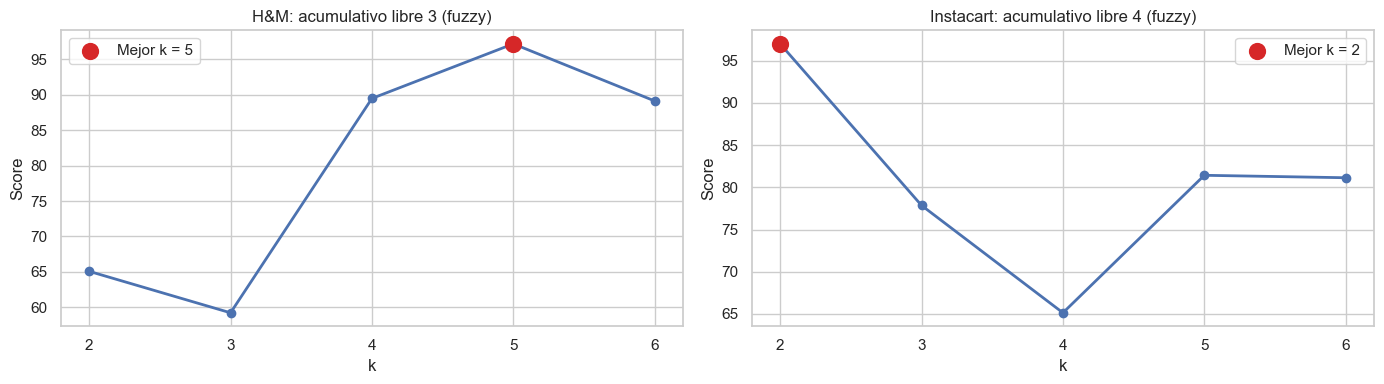

In [3]:
fig, axes = plt.subplots(1, len(seleccion), figsize=(14, 4), squeeze=False)
for ax, (_, fila) in zip(axes.ravel(), seleccion.iterrows()):
    if ruta_multimodelo.exists():
        resultados_multi = pd.read_csv(RESULTS_DIR / "multi_model_feature_validation.csv")
        evolucion = resultados_multi.loc[
            (resultados_multi["dataset"] == fila["dataset"])
            & (resultados_multi["subset"] == fila["subset"])
            & (resultados_multi["model"] == fila["modelo"])
        ].sort_values("k")
        columna_score = "score_general" if "score_general" in evolucion.columns else "score"
        valor_mejor = evolucion.loc[evolucion["k"] == fila["k"], columna_score].iloc[0]
    else:
        evolucion = resultados.loc[
            (resultados["dataset"] == fila["dataset"])
            & (resultados["subset"] == fila["subset"])
        ].sort_values("k")
        valor_mejor = fila["score_k"]
    columna_score = "score_general" if "score_general" in evolucion.columns else "score"
    ax.plot(evolucion["k"], evolucion[columna_score], marker="o", linewidth=2)
    ax.scatter(fila["k"], valor_mejor, s=130, color="#D62728", zorder=3, label=f"Mejor k = {fila['k']}")
    ax.set(title=f"{DATASETS[fila['dataset']]['titulo']}: {fila['subset']} ({fila['modelo']})", xlabel="k", ylabel="Score", xticks=evolucion["k"])
    ax.legend()
plt.tight_layout()
plt.show()

## 2. Ajuste final y perfiles de los clusters

El modelo se ajusta sobre todas las observaciones escaladas, mientras que las medias se calculan con las variables en sus unidades originales. La unión se hace por identificador para no depender del orden de las filas.

In [4]:
def ajustar_y_resumir(fila):
    dataset = fila["dataset"]
    config = DATASETS[dataset]
    columnas = [c.strip() for c in fila["columnas"].split("|")]
    escalado = pd.read_csv(config["scaled"])
    original = pd.read_csv(config["original"])
    if escalado[config["id_col"]].duplicated().any() or original[config["id_col"]].duplicated().any():
        raise ValueError(f"El identificador no es único en {dataset}.")

    _, labels = fit_clustering_model(
        fila["modelo"], int(fila["k"]), escalado[columnas]
    )
    asignacion = escalado[[config["id_col"]]].assign(cluster=labels)
    perfil = original.merge(asignacion, on=config["id_col"], how="inner", validate="one_to_one")

    columnas_perfil = [
        c for c in original.select_dtypes(include=np.number).columns
        if c != config["id_col"]
    ]
    columnas_no_usadas = [c for c in columnas_perfil if c not in columnas]
    medias_completas = perfil.groupby("cluster")[columnas_perfil].mean().round(3)
    medias_usadas = medias_completas[columnas]
    medias_no_usadas = medias_completas[columnas_no_usadas]
    tamanos = perfil["cluster"].value_counts().sort_index().rename("clientes").to_frame()
    tamanos["porcentaje"] = (100 * tamanos["clientes"] / len(perfil)).round(2)

    exportacion = tamanos.join(medias_completas)
    exportacion.to_csv(
        PROFILES_DIR / f"{dataset}_best_clustering_cluster_profiles.csv"
    )
    return {
        "columnas": columnas,
        "columnas_no_usadas": columnas_no_usadas,
        "columnas_perfil": columnas_perfil,
        "escalado": escalado,
        "labels": labels,
        "medias_usadas": medias_usadas,
        "medias_no_usadas": medias_no_usadas,
        "medias_completas": medias_completas,
        "tamanos": tamanos,
    }

analisis = {}
for _, fila in seleccion.iterrows():
    analisis[fila["dataset"]] = ajustar_y_resumir(fila)
    display(Markdown(f"### {DATASETS[fila['dataset']]['titulo']} — {fila['subset']}, k = {fila['k']}"))
    display(Markdown("**Tamaño de los clusters**"))
    display(analisis[fila["dataset"]]["tamanos"])
    display(Markdown("**Variables utilizadas para construir los clusters**"))
    display(analisis[fila["dataset"]]["medias_usadas"])
    display(Markdown("**Variables no utilizadas: caracterización posterior**"))
    display(analisis[fila["dataset"]]["medias_no_usadas"])

### H&M — acumulativo libre 3, k = 5

**Tamaño de los clusters**

,clientes,porcentaje
cluster,,
0,444658,32.64
1,156305,11.47
2,350004,25.69
3,292038,21.44
4,119276,8.76


**Variables utilizadas para construir los clusters**

,channel_2_ratio,std_days_between_purchases,avg_days_between_purchases
cluster,,,
0,0.877,74.366,77.434
1,0.011,0.041,3.275
2,0.997,0.053,0.425
3,0.188,66.320,84.782
4,0.896,0.125,190.685


**Variables no utilizadas: caracterización posterior**

... (4 outputs left out)

**Variables utilizadas para construir los clusters**

,recency,frequency,avg_days_between_orders,std_days_between_orders
cluster,,,,
0,23.566,7.501,17.210,11.884
1,9.168,25.409,8.839,6.559


**Variables no utilizadas: caracterización posterior**

,avg_basket_size,std_basket_size,unique_products,unique_aisles,unique_departments,reorder_ratio,product_variety_ratio
cluster,,,,,,,
0,9.699,4.108,43.275,22.115,9.745,0.340,0.660
1,10.258,4.459,90.342,34.664,12.143,0.544,0.456


## 3. Visualización de tamaños y perfiles

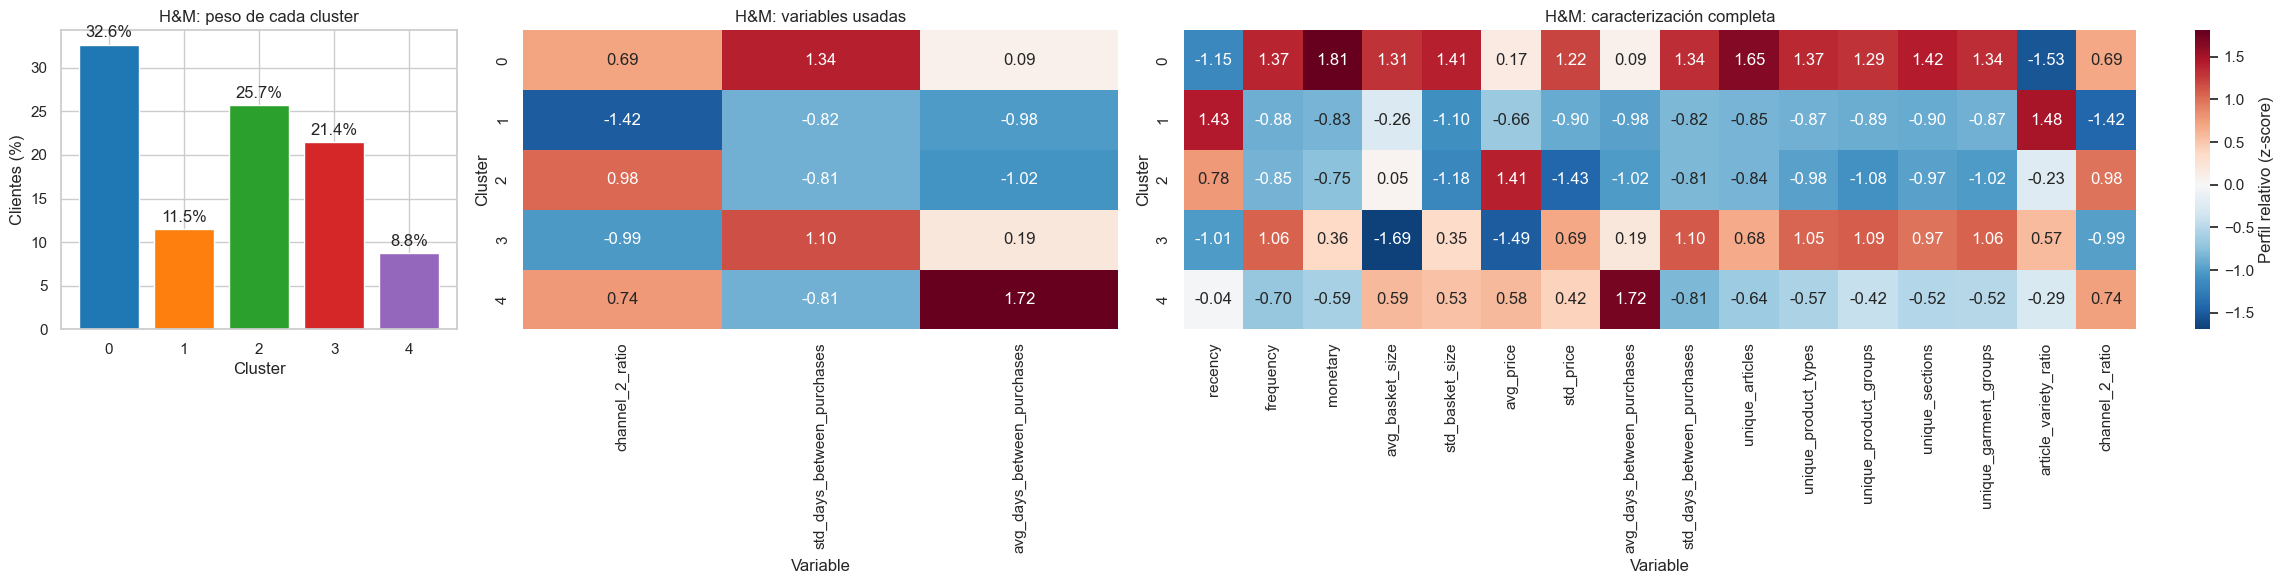

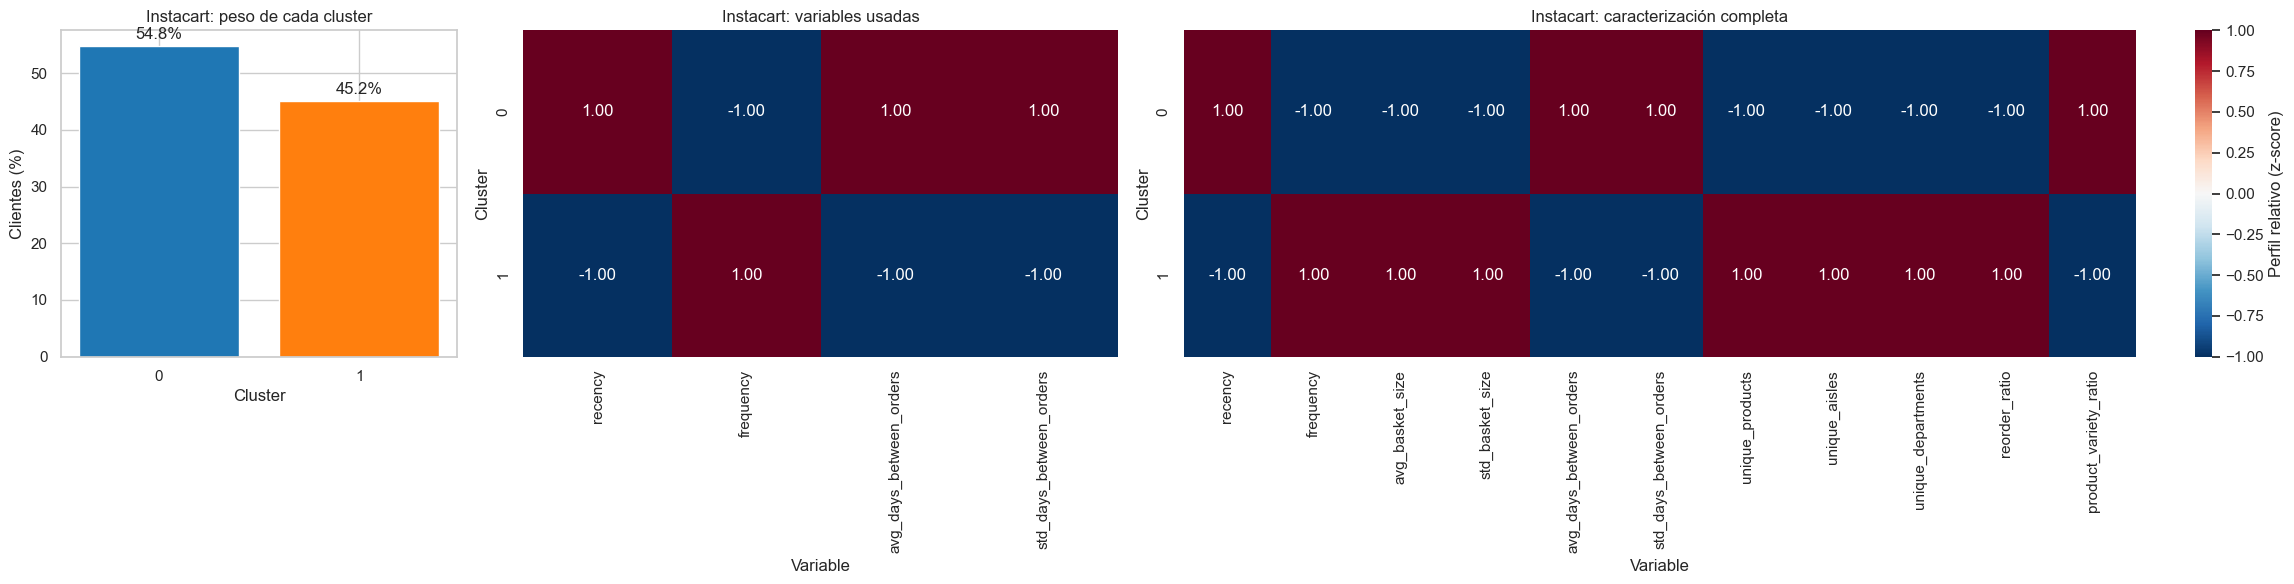

In [5]:
for dataset, datos in analisis.items():
    titulo = DATASETS[dataset]["titulo"]
    medias_usadas = datos["medias_usadas"]
    medias_completas = datos["medias_completas"]
    # Estandarización por variable para comparar patrones pese a las distintas unidades.
    perfiles_usados = (
        (medias_usadas - medias_usadas.mean(axis=0))
        / medias_usadas.std(axis=0, ddof=0).replace(0, 1)
    )
    perfiles_completos = (
        (medias_completas - medias_completas.mean(axis=0))
        / medias_completas.std(axis=0, ddof=0).replace(0, 1)
    )

    fig, axes = plt.subplots(
        1, 3, figsize=(24, 6),
        gridspec_kw={"width_ratios": [1, 1.5, 3]},
    )
    tamanos = datos["tamanos"]
    axes[0].bar(tamanos.index.astype(str), tamanos["porcentaje"], color=sns.color_palette("tab10", len(tamanos)))
    axes[0].set(title=f"{titulo}: peso de cada cluster", xlabel="Cluster", ylabel="Clientes (%)")
    axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3)
    sns.heatmap(perfiles_usados, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[1], cbar=False)
    axes[1].set(title=f"{titulo}: variables usadas", xlabel="Variable", ylabel="Cluster")
    sns.heatmap(perfiles_completos, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[2], cbar_kws={"label": "Perfil relativo (z-score)"})
    axes[2].set(title=f"{titulo}: caracterización completa", xlabel="Variable", ylabel="Cluster")
    plt.tight_layout()
    plt.show()

## 4. Proyecciones PCA complementarias

La primera proyección utiliza únicamente las variables con las que se construyeron los clusters y representa su geometría directa. La segunda utiliza todas las variables escaladas y sirve para caracterizar las mismas etiquetas desde el perfil completo. Esta segunda vista es descriptiva: una variable no utilizada puede diferenciar los grupos posteriormente, pero no causó su formación. Para que los gráficos sean comparables se emplean los mismos clientes y etiquetas en ambos espacios.

In [ ]:
fig, axes = plt.subplots(2, len(analisis), figsize=(16, 12), squeeze=False)
for columna_figura, (dataset, datos) in enumerate(analisis.items()):
    escalado = datos["escalado"]
    id_col = DATASETS[dataset]["id_col"]
    columnas_completas = [
        c for c in escalado.select_dtypes(include=np.number).columns
        if c != id_col
    ]
    rng = np.random.default_rng(RANDOM_STATE)
    indices = rng.choice(
        len(escalado), size=min(PCA_SAMPLE_SIZE, len(escalado)), replace=False
    )
    labels_muestra = datos["labels"][indices]

    espacios = [
        ("espacio del modelo", datos["columnas"]),
        ("perfil completo", columnas_completas),
    ]
    for fila_figura, (nombre_espacio, columnas_pca) in enumerate(espacios):
        ax = axes[fila_figura, columna_figura]
        X_muestra = escalado.iloc[indices][columnas_pca]
        pca = PCA(n_components=2, random_state=RANDOM_STATE)
        coords = pca.fit_transform(X_muestra)
        for cluster in np.unique(labels_muestra):
            mascara = labels_muestra == cluster
            ax.scatter(
                coords[mascara, 0], coords[mascara, 1],
                s=8, alpha=0.30, label=f"Cluster {cluster}",
            )
        varianza = 100 * pca.explained_variance_ratio_.sum()
        ax.set(
            title=(
                f"{DATASETS[dataset]['titulo']} — {nombre_espacio}\n"
                f"PCA: {varianza:.1f}% de varianza"
            ),
            xlabel="Componente principal 1",
            ylabel="Componente principal 2",
        )
        ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

## 5. Conclusiones automáticas

In [7]:
for _, fila in seleccion.iterrows():
    dataset = fila["dataset"]
    datos = analisis[dataset]
    dominante = datos["tamanos"]["porcentaje"].idxmax()
    porcentaje = datos["tamanos"].loc[dominante, "porcentaje"]
    display(Markdown(
        f"**{DATASETS[dataset]['titulo']}**: el subset recomendado es **{fila['subset']}** "
        f"con **{fila['n_variables']} variables** y su mejor solución usa **{fila['modelo']} con k={fila['k']}**. "
        f"El cluster más grande es el **{dominante}**, con un **{porcentaje:.2f}%** de los clientes. "
        f"Silhouette: **{fila['silhouette']:.3f}**; Calinski-Harabasz: **{fila['calinski_harabasz']:.1f}**; "
        f"Davies-Bouldin: **{fila['davies_bouldin']:.3f}**."
    ))

display(Markdown("Las etiquetas numéricas de los clusters no implican un orden. La interpretación de negocio debe basarse en la tabla de medias originales y en el mapa de perfiles relativos."))

**H&M**: el subset recomendado es **acumulativo libre 3** con **3 variables** y su mejor solución usa **fuzzy con k=5**. El cluster más grande es el **0**, con un **32.64%** de los clientes. Silhouette: **0.652**; Calinski-Harabasz: **55333.6**; Davies-Bouldin: **0.567**.

**Instacart**: el subset recomendado es **acumulativo libre 4** con **4 variables** y su mejor solución usa **fuzzy con k=2**. El cluster más grande es el **0**, con un **54.83%** de los clientes. Silhouette: **0.406**; Calinski-Harabasz: **29412.6**; Davies-Bouldin: **0.954**.

Las etiquetas numéricas de los clusters no implican un orden. La interpretación de negocio debe basarse en la tabla de medias originales y en el mapa de perfiles relativos.